## import functions/libraries

In [1]:
import geopandas as gpd
import rasterio, pandas

from functions.estimate_biomass import estimate_biomass
from functions.get_diameter import *
from functions.get_treespecies import *
from functions.get_treeheight import *
import matplotlib.pyplot as plt

## load polygons

In [2]:
trees21 = gpd.read_file("/home/berberic/Documents/allometry/trees/bonn_2021.geojson")
trees16 = gpd.read_file("/home/berberic/Documents/allometry/trees/bonn_2016.geojson")

/home/berberic/Documents/code/biomass/.venv/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: Several features with id = 4 have been found. Altering it to be unique. This warning will not be emitted anymore for this layer
  return ogr_read(
/home/berberic/Documents/code/biomass/.venv/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: Several features with id = 0 have been found. Altering it to be unique. This warning will not be emitted anymore for this layer
  return ogr_read(


## calculate diameter

In [3]:
trees16 = get_diameter(trees16)
trees21 = get_diameter(trees21)

diameter derived
diameter derived


## get tree species

In [4]:
trees16 = get_treespecies(polygon=trees16, raster_path= "/home/berberic/Documents/allometry/treespecies/treespecies_2016_bonn_nadellaub.tif")
trees21 = get_treespecies(polygon=trees21, raster_path="/home/berberic/Documents/allometry/treespecies/treespecies_2021_bonn_nadellaub.tif")

species derived
species derived


## get tree height

In [5]:
treeheights16 = get_treeheight_fromDLR(polygon=trees16, year = 2016)
treeheights21 = get_treeheight_fromDLR(polygon=trees21, year = 2021)

The dataset begins in 2017. For all prior years, 2017 is used.
treeheight derived
treeheight derived


In [6]:
# handle zeros in treeheight by using mean instead
remove_zeros = True

if remove_zeros:
    treeheights16.loc[treeheights16["treeheight"] == 0, "treeheight"] = treeheights16["treeheight"].mean()
    treeheights21.loc[treeheights21["treeheight"] == 0, "treeheight"] = treeheights21["treeheight"].mean()

plot_treeheight = False

if plot_treeheight:
    treeheights16["treeheight"].hist(bins=25)
    plt.show()
    treeheights21["treeheight"].hist(bins=25)
    plt.show()

## estimate biomass

In [7]:
biomass16 = estimate_biomass(treeheights16)
biomass21 = estimate_biomass(treeheights21)

biomass derived
biomass derived


In [8]:
total_deadAGB16 = sum(biomass16["AGB"])
print(total_deadAGB16/1000)
total_deadAGB21 = sum(biomass21["AGB"])
print(total_deadAGB21/1000)

1294.666594664576
19957.12249747298


## Plots

Mean biomass per dead tree in 2016: 278.30322327269477
Mean biomass per dead tree in 2021: 292.95288734473877


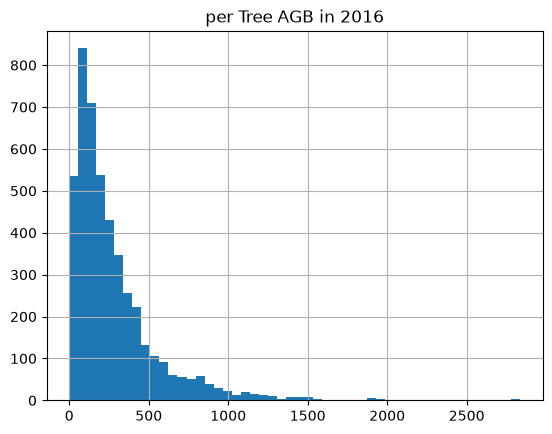

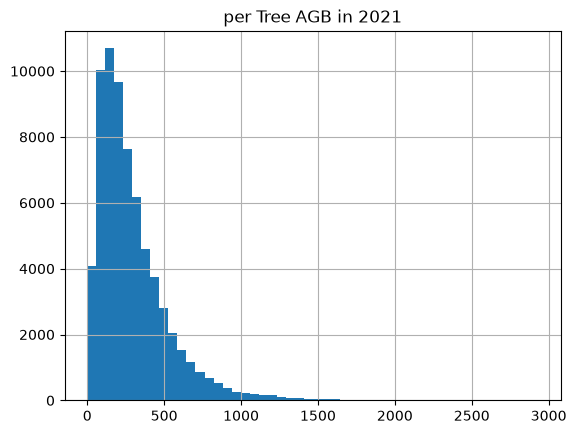

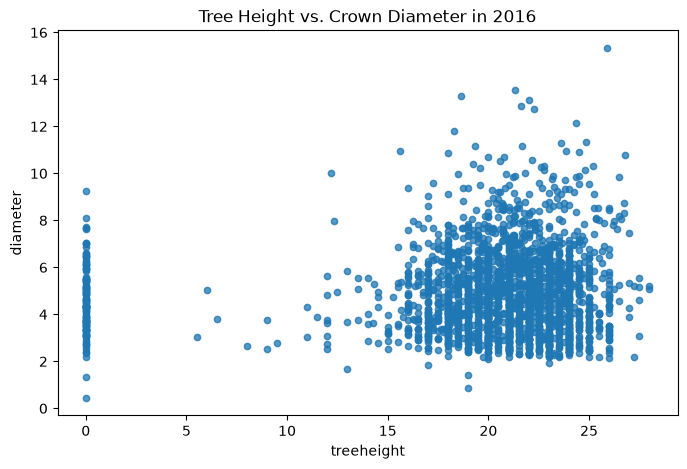

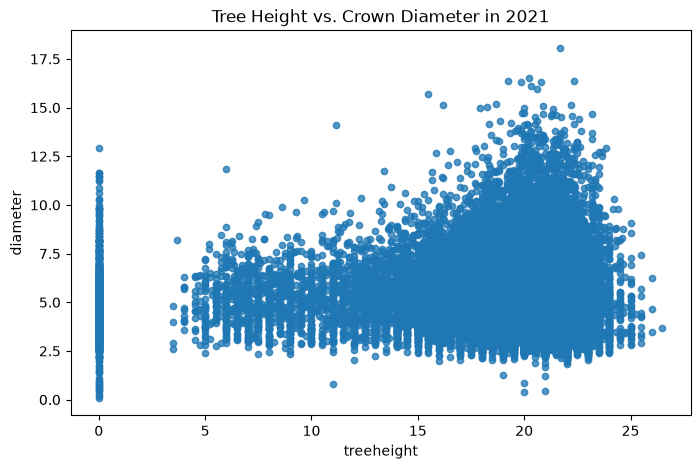

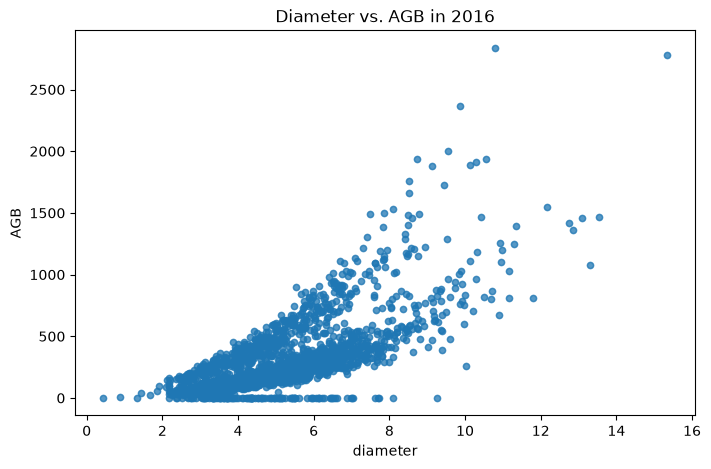

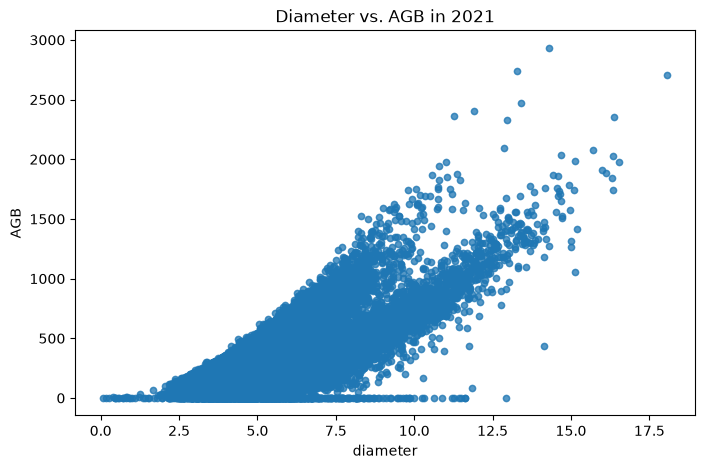

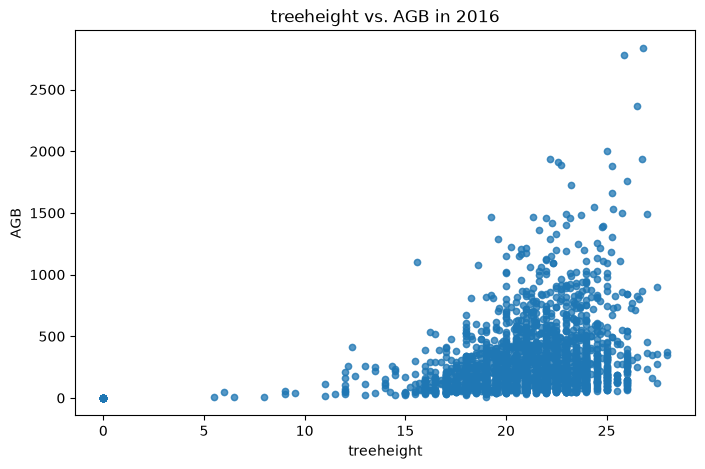

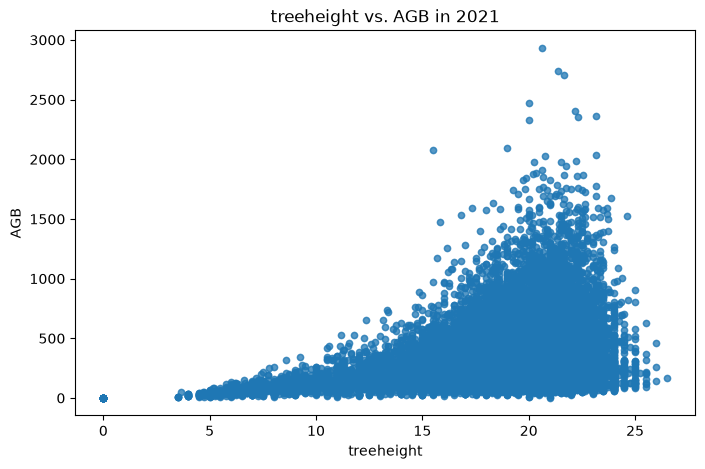

In [9]:
print(f"Mean biomass per dead tree in 2016: {biomass16['AGB'].mean()}")
print(f"Mean biomass per dead tree in 2021: {biomass21['AGB'].mean()}")

biomass16["AGB"].hist(bins=50)
plt.title("per Tree AGB in 2016")
plt.show()
biomass21["AGB"].hist(bins=50)
plt.title("per Tree AGB in 2021")
plt.show()

biomass16.plot.scatter(x="treeheight", y="diameter", figsize=(8, 5), alpha=0.5, title="Tree Height vs. Crown Diameter in 2016")
plt.show()
biomass21.plot.scatter(x="treeheight", y="diameter", figsize=(8, 5), alpha=0.5, title="Tree Height vs. Crown Diameter in 2021")
plt.show()

biomass16.plot.scatter(x="diameter", y="AGB", figsize=(8, 5), alpha=0.5, title="Diameter vs. AGB in 2016")
plt.show()
biomass21.plot.scatter(x="diameter", y="AGB", figsize=(8, 5), alpha=0.5, title="Diameter vs. AGB in 2021")
plt.show()

biomass16.plot.scatter(x="treeheight", y="AGB", figsize=(8, 5), alpha=0.5, title="treeheight vs. AGB in 2016")
plt.show()
biomass21.plot.scatter(x="treeheight", y="AGB", figsize=(8, 5), alpha=0.5, title="treeheight vs. AGB in 2021")
plt.show()